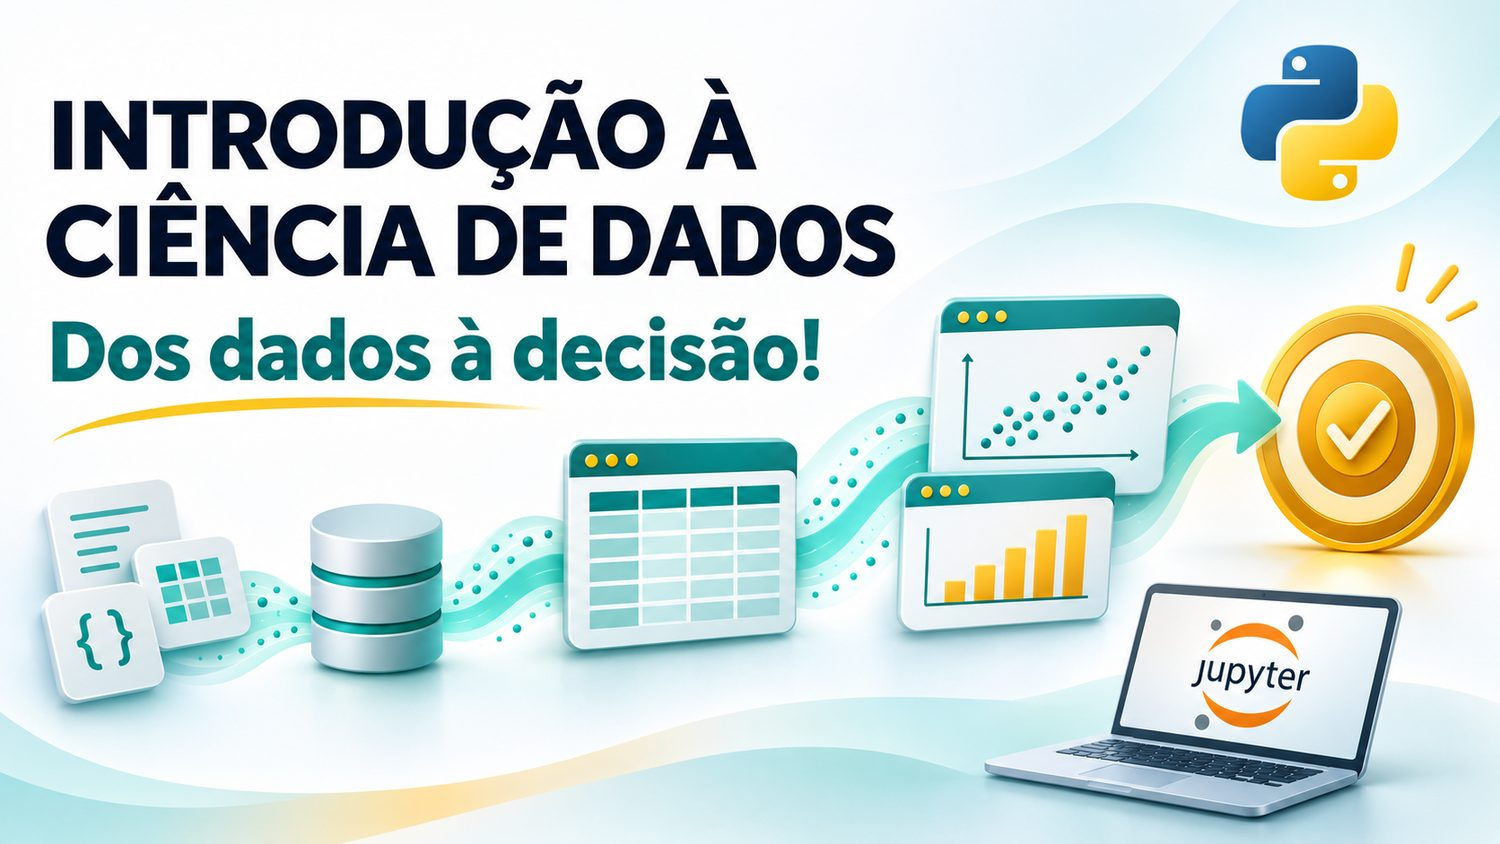

[![Abrir no Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ricardoluizdasilva/mestrado_ai_estudos/blob/main/Introdu%C3%A7%C3%A3o%20%C3%A0%20Ci%C3%AAncia%20de%20Dados/tutorial_ciencia_dados/modulo_1_do_problema_a_decisao/01_Dos_Dados_a_Decisao.ipynb)

# Capítulo 1 – Dos dados à decisão

Quase todas as organizações guardam dados: vendas, marcações, leituras de sensores, cliques. Muito poucas conseguem dizer que decisão ficou melhor por causa deles. Este capítulo mostra o caminho entre uma tabela de registos e uma decisão, e explica o que é a ciência de dados e que competências junta.

> **Objetivos:** distinguir dado, informação, conhecimento e decisão; caracterizar *big data* pelos cinco V; definir ciência de dados e as competências que combina; reconhecer onde se aplica.

**Pré-requisitos:** noções básicas de Python e de pandas (ver o tutorial [Introdução ao Python](../../../Introdu%C3%A7%C3%A3o%20%C3%A0%20Programa%C3%A7%C3%A3o/tutorial_python), capítulos 22 a 24). Podes ler o capítulo sem programar: basta executar as células por ordem.

## Preparação

A primeira célula importa as bibliotecas e define três funções pequenas (`tela`, `caixa` e `seta`) que usamos para desenhar os esquemas do tutorial.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, FancyArrowPatch, FancyBboxPatch

# Cores usadas em todo o tutorial (sempre com o mesmo significado)
AZUL, VERDE, VIOLETA, LARANJA = "#2a78d6", "#1baf7a", "#6250d6", "#eb6834"
BOM, MAU, AVISO, CINZA, TINTA = "#0ca30c", "#d03b3b", "#fab219", "#b4bdc8", "#131c26"

plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.titleweight": "bold",
                     "axes.titlelocation": "left"})


def tela(largura, altura, tamanho=(10, 3)):
    """Cria uma figura vazia, sem eixos, para desenhar esquemas."""
    fig, ax = plt.subplots(figsize=tamanho)
    ax.set_xlim(0, largura)
    ax.set_ylim(0, altura)
    ax.axis("off")
    return fig, ax


def caixa(ax, x, y, largura, altura, texto, cor, tamanho=10, negrito=False):
    """Desenha uma caixa arredondada com texto centrado."""
    ax.add_patch(FancyBboxPatch((x, y), largura, altura, boxstyle="round,pad=0.02,rounding_size=0.1",
                                fc=cor + "30", ec=cor, lw=1.6))
    ax.text(x + largura / 2, y + altura / 2, texto, ha="center", va="center", color=TINTA,
            fontsize=tamanho, linespacing=1.45, fontweight="bold" if negrito else "normal")


def seta(ax, inicio, fim, cor="#465463", **opcoes):
    """Desenha uma seta entre dois pontos."""
    opcoes.setdefault("arrowstyle", "-|>")
    ax.add_patch(FancyArrowPatch(inicio, fim, mutation_scale=14, color=cor, lw=1.5, **opcoes))

## Ter dados não é ter respostas

Imagina uma rede de clínicas com um problema conhecido: há pacientes que marcam consulta e não aparecem. A vaga fica vazia, o médico fica parado e outra pessoa podia ter sido atendida.

A clínica tem anos de registos. Tem, portanto, «muitos dados». Mesmo assim, ninguém sabe responder a perguntas simples:

- Quem falta mais, e quando?
- Os lembretes por SMS funcionam?
- A quem vale a pena telefonar na véspera?

Acumular registos não responde a nenhuma destas perguntas. É preciso alguém que faça a pergunta certa, escolha os dados que a podem responder, os analise com cuidado e traduza o resultado numa ação. É esse trabalho que este tutorial ensina.

> **Ideia central:** mais dados não significam automaticamente melhor evidência nem melhores decisões.

Vamos usar este caso (as faltas a consultas) ao longo de todo o módulo. Os dados são **sintéticos**: são gerados pela função abaixo, não pertencem a nenhuma clínica real, e por isso podes experimentar à vontade.

In [2]:
def gerar_consultas(n=10_000, semente=42):
    """Gera marcações de consultas de uma clínica fictícia (dados sintéticos)."""
    rng = np.random.default_rng(semente)
    antecedencia = rng.gamma(2.0, 9.0, n).round().clip(0, 90).astype(int)
    idade = rng.integers(18, 90, n)
    faltas_anteriores = rng.poisson(0.4, n)
    dia = rng.choice(["seg", "ter", "qua", "qui", "sex"], n)
    # A clínica envia mais lembretes por SMS a quem já faltou antes
    lembrete = rng.random(n) < 0.05 + 0.70 * (faltas_anteriores >= 1)
    z = (-3.7 + 0.05 * antecedencia + 1.0 * faltas_anteriores
         - 0.012 * (idade - 18) - 0.6 * lembrete + 0.3 * (dia == "seg"))
    faltou = rng.random(n) < 1 / (1 + np.exp(-z))
    return pd.DataFrame({"antecedencia_dias": antecedencia, "idade": idade,
                         "faltas_anteriores": faltas_anteriores, "dia_semana": dia,
                         "lembrete": lembrete, "faltou": faltou})


consultas = gerar_consultas()
consultas.head()

,antecedencia_dias,idade,faltas_anteriores,dia_semana,lembrete,faltou
0,19,55,2,qua,True,False
1,26,42,2,sex,True,False
2,17,48,0,ter,False,False
3,15,34,1,ter,False,False
4,28,43,0,sex,False,False


Cada linha é uma marcação. As colunas são:

| Coluna | Significado |
| --- | --- |
| `antecedencia_dias` | dias entre o momento da marcação e a consulta |
| `idade` | idade do paciente |
| `faltas_anteriores` | número de faltas anteriores do paciente |
| `dia_semana` | dia da consulta |
| `lembrete` | se foi enviado um lembrete por SMS |
| `faltou` | se o paciente faltou (`True`) ou compareceu (`False`) |

## *Big data* e os cinco V

Chama-se *big data* a conjuntos de dados tão grandes, rápidos ou variados que as ferramentas tradicionais (uma folha de cálculo, uma base de dados num só computador) deixam de chegar. A caracterização mais usada nasceu em 2001, quando o analista Doug Laney descreveu três dimensões. Mais tarde juntaram-se duas.

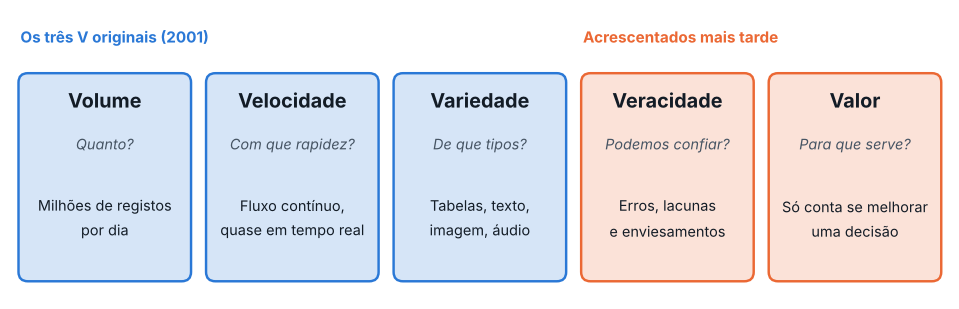

In [3]:
vs = [("Volume", "Quanto?", "Milhões de registos\npor dia", AZUL),
      ("Velocidade", "Com que rapidez?", "Fluxo contínuo,\nquase em tempo real", AZUL),
      ("Variedade", "De que tipos?", "Tabelas, texto,\nimagem, áudio", AZUL),
      ("Veracidade", "Podemos confiar?", "Erros, lacunas\ne enviesamentos", LARANJA),
      ("Valor", "Para que serve?", "Só conta se melhorar\numa decisão", LARANJA)]

fig, ax = tela(10, 3.1, (11, 3.4))
for i, (nome, pergunta, exemplo, cor) in enumerate(vs):
    caixa(ax, 0.1 + i * 2, 0.2, 1.8, 2.2, "", cor)
    ax.text(1.0 + i * 2, 2.05, nome, ha="center", fontsize=13, fontweight="bold", color=TINTA)
    ax.text(1.0 + i * 2, 1.6, pergunta, ha="center", fontsize=9.5, style="italic", color="#465463")
    ax.text(1.0 + i * 2, 0.85, exemplo, ha="center", va="center", fontsize=9.5, color=TINTA, linespacing=1.4)
ax.text(0.1, 2.75, "Os três V originais (2001)", color=AZUL, fontweight="bold")
ax.text(6.1, 2.75, "Acrescentados mais tarde", color=LARANJA, fontweight="bold")
plt.show()

No caso da clínica:

| V | Na rede de clínicas |
| --- | --- |
| **Volume** | Dez mil marcações por mês, multiplicadas por vários anos e várias unidades. |
| **Velocidade** | As marcações e os cancelamentos chegam a toda a hora; a decisão de telefonar tem de ser tomada na véspera. |
| **Variedade** | Tabelas de marcações, notas de texto livre da receção, gravações de chamadas. |
| **Veracidade** | Uma falta registada pode ser um cancelamento que ninguém anotou. |
| **Valor** | Os registos só valem alguma coisa se ajudarem a ter menos vagas vazias. |

Os dois últimos V são os que mais importam neste tutorial. A **veracidade** é o tema do capítulo 4. O **valor** é o tema de todos os outros.

## De dados a decisão em quatro passos

Entre um registo isolado e uma decisão há três transformações. Cada uma acrescenta contexto ao passo anterior.

| Etapa | O que é | Pergunta que responde |
| --- | --- | --- |
| **Dados** | Factos em bruto, sem contexto | O que foi registado? |
| **Informação** | Dados organizados e resumidos | O que aconteceu, onde e quando? |
| **Conhecimento** | Padrões que se mantêm e se podem comparar | O que aprendemos sobre como isto funciona? |
| **Decisão** | Uma ação escolhida, com responsável e objetivo | O que vamos fazer? |

Vamos percorrer as quatro etapas com os dados da clínica.

### 1. Dados

Uma linha da tabela, sozinha, não diz nada de útil:

In [4]:
consultas.iloc[[0]]

,antecedencia_dias,idade,faltas_anteriores,dia_semana,lembrete,faltou
0,19,55,2,qua,True,False


### 2. Informação

Quando resumimos as dez mil linhas, aparece a dimensão do problema.

In [5]:
total = len(consultas)
faltas = int(consultas["faltou"].sum())
taxa = consultas["faltou"].mean()
print(f"Marcações: {total:,}".replace(",", " "))
print(f"Faltas:    {faltas}")
print(f"Taxa de faltas: {taxa:.1%}")

Marcações: 10 000
Faltas:    726
Taxa de faltas: 7.3%


E quando cruzamos as faltas com a antecedência da marcação, aparece *onde* está o problema.

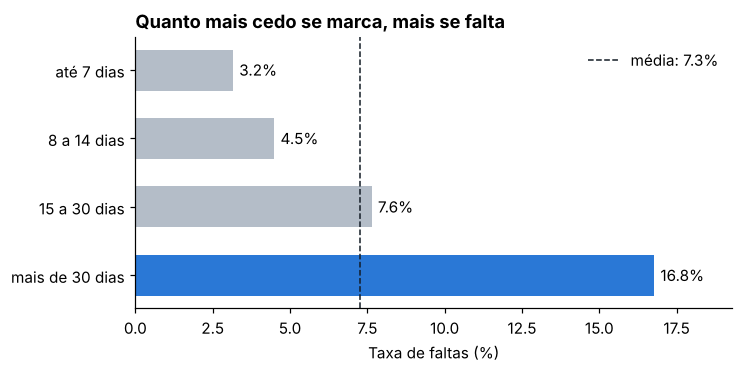

,taxa,marcacoes
antecedencia_dias,,
até 7 dias,3.2,1993
8 a 14 dias,4.5,2758
15 a 30 dias,7.6,3741
mais de 30 dias,16.8,1508


In [6]:
faixas = pd.cut(consultas["antecedencia_dias"], [-1, 7, 14, 30, 90],
                labels=["até 7 dias", "8 a 14 dias", "15 a 30 dias", "mais de 30 dias"])
por_faixa = consultas.groupby(faixas, observed=True)["faltou"].agg(taxa="mean", marcacoes="size")

fig, ax = plt.subplots(figsize=(7, 3.2))
barras = ax.barh(por_faixa.index, por_faixa["taxa"] * 100, color=[CINZA, CINZA, CINZA, AZUL], height=0.6)
ax.bar_label(barras, labels=[f"{v:.1%}" for v in por_faixa["taxa"]], padding=4)
ax.axvline(taxa * 100, color=TINTA, lw=1, ls="--", label=f"média: {taxa:.1%}")
ax.legend(frameon=False, loc="upper right")
ax.invert_yaxis()
ax.set_xlabel("Taxa de faltas (%)")
ax.set_title("Quanto mais cedo se marca, mais se falta")
ax.set_xlim(0, por_faixa["taxa"].max() * 115)
plt.show()

por_faixa.assign(taxa=lambda t: (t["taxa"] * 100).round(1))

### 3. Conhecimento

Um número isolado ainda não é conhecimento. Passa a ser quando verificamos que o padrão **se mantém** em grupos diferentes, e por isso é de esperar que se repita.

A célula seguinte verifica se a relação entre antecedência e faltas existe em todos os dias da semana.

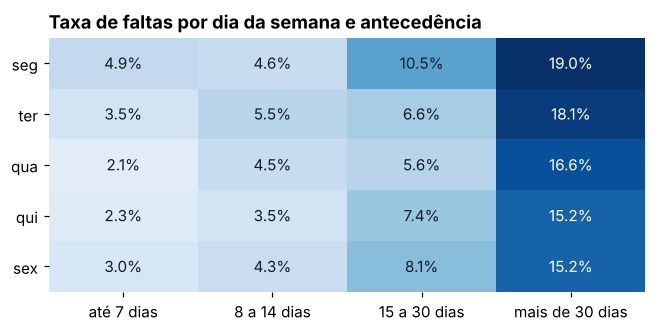

In [7]:
tabela = consultas.pivot_table(index="dia_semana", columns=faixas, values="faltou",
                               aggfunc="mean", observed=True)
tabela = tabela.loc[["seg", "ter", "qua", "qui", "sex"]] * 100

fig, ax = plt.subplots(figsize=(7, 3))
imagem = ax.imshow(tabela, cmap="Blues", vmin=0, aspect="auto")
ax.set_xticks(range(4), tabela.columns)
ax.set_yticks(range(5), tabela.index)
for i in range(5):
    for j in range(4):
        valor = tabela.iloc[i, j]
        ax.text(j, i, f"{valor:.1f}%", ha="center", va="center",
                color="white" if valor > tabela.values.max() * 0.6 else TINTA)
ax.set_title("Taxa de faltas por dia da semana e antecedência")
ax.spines[:].set_visible(False)
plt.show()

Em todas as linhas a taxa cresce da esquerda para a direita. O padrão não depende do dia: **as marcações feitas com mais de um mês de antecedência faltam várias vezes mais do que as feitas na própria semana.** Isto já é conhecimento, porque permite antecipar o que vai acontecer com as marcações de amanhã.

### 4. Decisão

O conhecimento só se transforma em valor quando alguém decide fazer alguma coisa com ele. Uma decisão bem escrita diz **o quê**, **quem**, **quando** e **com que objetivo**:

> A receção (quem) telefona na véspera (quando) aos pacientes com consultas marcadas há mais de 30 dias (o quê), para reduzir as vagas vazias sem aumentar o tempo de espera de quem marca (objetivo).

O esquema seguinte junta as quatro etapas, com os números calculados acima.

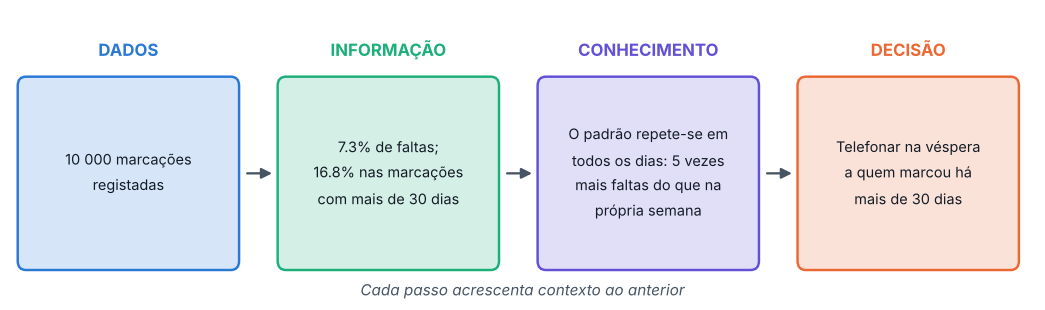

In [8]:
pior = por_faixa["taxa"].iloc[-1]
melhor = por_faixa["taxa"].iloc[0]
etapas = [("DADOS", f"{total:,} marcações\nregistadas".replace(",", " "), AZUL),
          ("INFORMAÇÃO", f"{taxa:.1%} de faltas;\n{pior:.1%} nas marcações\ncom mais de 30 dias", VERDE),
          ("CONHECIMENTO", f"O padrão repete-se em\ntodos os dias: {pior / melhor:.0f} vezes\nmais faltas do que na\nprópria semana", VIOLETA),
          ("DECISÃO", "Telefonar na véspera\na quem marcou há\nmais de 30 dias", LARANJA)]

fig, ax = tela(12.2, 3, (12, 3.2))
for i, (titulo, texto, cor) in enumerate(etapas):
    x = 0.1 + i * 3.1
    caixa(ax, x, 0.15, 2.6, 2.1, texto, cor, 9.5)
    ax.text(x + 1.3, 2.5, titulo, ha="center", fontweight="bold", color=cor, fontsize=11)
    if i < 3:
        seta(ax, (x + 2.68, 1.2), (x + 3.05, 1.2))
ax.text(6.1, -0.15, "Cada passo acrescenta contexto ao anterior", ha="center", color="#465463", style="italic")
plt.show()

> **Cuidado:** a decisão acima parece razoável, mas ainda não sabemos se é boa. Telefonar a toda a gente com mais de 30 dias pode custar mais do que as vagas que recupera. O capítulo 3 mostra como avaliar isso.

## O que é a ciência de dados

A **ciência de dados** é a disciplina que transforma dados em evidência e em decisões informadas. Para isso junta quatro ingredientes:

- **raciocínio científico**: formular hipóteses, duvidar das explicações fáceis, procurar o que as pode contrariar;
- **estatística**: distinguir um padrão do acaso e medir a incerteza;
- **computação**: tratar volumes de dados que não cabem numa folha de cálculo e repetir a análise sem erros;
- **conhecimento do domínio**: saber o que os dados representam e que respostas seriam úteis.

O trabalho é **iterativo**. Faz-se uma pergunta, olha-se para os dados, analisa-se, avalia-se e comunica-se, e quase sempre o que se aprende obriga a voltar atrás e a refazer a pergunta.

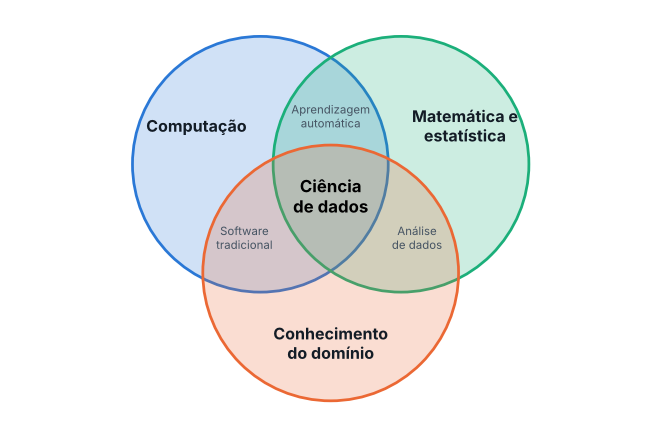

In [9]:
fig, ax = tela(10, 6.4, (7.5, 5))
for (x, y), cor in zip([(3.9, 4.0), (6.1, 4.0), (5.0, 2.3)], [AZUL, VERDE, LARANJA]):
    ax.add_patch(Circle((x, y), 2.0, fc=cor + "38", ec=cor, lw=1.8))
ax.set_aspect("equal")
rotulos = [(2.9, 4.6, "Computação", True), (7.1, 4.6, "Matemática e\nestatística", True),
           (5.0, 1.2, "Conhecimento\ndo domínio", True), (5.0, 4.75, "Aprendizagem\nautomática", False),
           (3.65, 2.85, "Software\ntradicional", False), (6.35, 2.85, "Análise\nde dados", False)]
for x, y, texto, forte in rotulos:
    ax.text(x, y, texto, ha="center", va="center", fontsize=10.5 if forte else 7.5,
            fontweight="bold" if forte else "normal", color=TINTA if forte else "#465463")
ax.text(5.0, 3.5, "Ciência\nde dados", ha="center", va="center", fontweight="bold", fontsize=11)
plt.show()

O esquema mostra porque é que a ciência de dados é difícil de fazer sozinho:

- computação e estatística **sem domínio** produzem modelos tecnicamente corretos que respondem à pergunta errada;
- domínio e estatística **sem computação** ficam limitados a amostras pequenas e a análises que ninguém consegue repetir;
- computação e domínio **sem estatística** produzem sistemas que confundem coincidências com padrões.

Há uma quarta competência que o esquema não mostra: **comunicar**. Uma análise que ninguém compreende não muda decisão nenhuma. Saber interpretar um resultado, explicá-lo com clareza e escolher o gráfico certo faz parte do trabalho.

## Onde se aplica

Alguns usos comuns, organizados pelo tipo de pergunta a que respondem (os quatro tipos são o tema do capítulo 2):

| Aplicação | O que faz | Tipo de pergunta |
| --- | --- | --- |
| Segmentação de clientes | Agrupa clientes com comportamento semelhante | Descrever |
| Análise de causas de avarias | Procura os fatores associados a falhas de equipamento | Explicar |
| Previsão de abandono (*churn*) | Estima quem vai deixar de ser cliente | Prever |
| Deteção de fraude | Sinaliza transações suspeitas | Prever |
| Sistemas de recomendação | Estimam o que cada pessoa vai querer ver ou comprar | Prever |
| Valor do cliente ao longo do tempo | Estima a receita futura de cada cliente | Prever |
| Preços dinâmicos | Ajustam o preço à procura | Decidir |
| Marketing dirigido | Escolhe a quem enviar que campanha | Decidir |
| Planeamento de turnos e de stocks | Decide quantas pessoas ou unidades ter disponíveis | Decidir |

## Exercícios

Tenta resolver cada exercício antes de abrir a solução. Há sempre mais do que uma solução correta.

### `Exercício 1` – Dado, informação, conhecimento ou decisão?

Classifica cada frase:

1. «A paciente n.º 4 812 faltou à consulta de 3 de março.»
2. «Às segundas-feiras falta-se mais do que nos outros dias, e isso acontece em todas as faixas de antecedência.»
3. «Na segunda-feira passada houve 31 faltas em 340 consultas.»
4. «A partir de abril, as consultas de segunda-feira passam a ter confirmação por telefone.»

<details>
<summary><b>Ver uma solução possível</b></summary>

1. **Dado**: um facto isolado, sem contexto.
2. **Conhecimento**: um padrão que se mantém em vários grupos e permite antecipar.
3. **Informação**: dados resumidos, com contexto (quando, quantos).
4. **Decisão**: uma ação, com momento e alvo definidos.

</details>

### `Exercício 2` – Informação por dia da semana

Calcula a taxa de faltas por dia da semana e mostra-a num gráfico de barras. Em que dia se falta mais?

In [10]:
# Escreve aqui o código do exercício 2

<details>
<summary><b>Ver uma solução possível</b></summary>

```python
ordem = ["seg", "ter", "qua", "qui", "sex"]
por_dia = consultas.groupby("dia_semana")["faltou"].mean().loc[ordem] * 100

fig, ax = plt.subplots(figsize=(6, 3))
barras = ax.bar(por_dia.index, por_dia, color=[AZUL if d == por_dia.idxmax() else CINZA for d in ordem])
ax.bar_label(barras, fmt="%.1f%%", padding=3)
ax.set_ylabel("Taxa de faltas (%)")
plt.show()
```

Falta-se mais à segunda-feira. As diferenças entre os outros dias são pequenas e podem dever-se ao acaso.

</details>

### `Exercício 3` – Que V está em causa?

Indica o V mais relevante em cada situação:

1. Uma cadeia de supermercados recebe os talões de 400 lojas e precisa de detetar ruturas de stock no próprio dia.
2. Um hospital quer analisar em conjunto análises clínicas, relatórios escritos e radiografias.
3. Uma autarquia instalou sensores de ruído, mas metade está mal calibrada.
4. Uma empresa guarda todos os cliques do seu site há cinco anos e nunca os analisou.

<details>
<summary><b>Ver uma solução possível</b></summary>

1. **Velocidade** (e volume): a resposta só serve se chegar no próprio dia.
2. **Variedade**: números, texto e imagem.
3. **Veracidade**: não se pode confiar nas leituras.
4. **Valor**: há volume, mas nenhuma decisão melhorou por causa dele.

</details>

## Verifica o que aprendeste

- [ ] Sei explicar porque é que ter muitos dados não garante boas decisões.
- [ ] Sei distinguir dado, informação, conhecimento e decisão, e dar um exemplo de cada.
- [ ] Sei enumerar os cinco V e dizer quais são os três originais.
- [ ] Sei definir ciência de dados e indicar os ingredientes que junta.
- [ ] Sei explicar o que se perde quando falta uma das três áreas do diagrama.

## Leitura recomendada

- https://en.wikipedia.org/wiki/Data_science
- https://en.wikipedia.org/wiki/Big_data
- https://en.wikipedia.org/wiki/DIKW_pyramid